# Step 2: Multi-Cloud FinOps Anomaly Detection & Diagnostic Engine
**Abhi Cloud Tech — Enterprise FinOps & Multi-Cloud Optimization Platform**  
*Lead Architect: Abhishek (FinOps ML Validation & Tuning Specialist)*

---

### Executive Overview & Industry Problem
Unmonitored cloud spend anomalies silently erode enterprise operating margins. Static threshold alerting (e.g. "alert if daily spend exceeds $500") generates unacceptable alert fatigue and high false-positive rates due to weekly cyclicality, end-of-month batch jobs, and legitimate architectural scaling.

### Production Multi-Layer Architecture
1. **Multivariate Isolation Forest (Scikit-Learn)**: Evaluates normalized multidimensional telemetry (Daily Spend, vCPU Hours, CPU Utilization %, Data Egress, Storage Volume, Cost-per-CPU Ratio).
2. **28-Day Hierarchical Rolling Median Baseline**: Resilient against sustained 7-8 day anomalous drift (e.g. idle clusters or unattached disks) with cross-sectional fallback during warmup.
3. **Multi-Cloud Root-Cause Diagnostic Rules**:
   - **Orphan Snapshots & Stale Machine Images**: High storage volume, zero compute utilization, sustained daily cost.
   - **Zombie Compute Clusters**: High vCPU allocation with <15% average CPU utilization.
   - **Runaway Egress Transfer**: Network egress surges exceeding 5x historical baseline.
   - **Storage Sprawl**: High-performance provisioned IOPS detached from active compute.
4. **Monetary Severity Quantification**: Critical (> $400 spike or Z > 3.8), High (> $180 spike or Z > 2.2), Medium.

### Data Science Validation Rigor
- **Strict Chronological Train-Test Split**: Temporal out-of-time holdout (85% Train, 15% Test) strictly prohibiting future lookahead leakage.
- **5-Fold TimeSeriesSplit (Expanding Window Cross-Validation)**: Verifying generalization stability without lookahead bias.
- **Diagnostic Evaluation Suite**: Confusion Matrix, ROC-AUC, Precision-Recall Curve (AP), Telemetry Feature Correlation Heatmap, and Score Density Distributions.


### Block 1: Imports & Database Ingestion


In [1]:
import os
import sys
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(BASE_DIR) not in sys.path:
    sys.path.insert(0, str(BASE_DIR))

from src.database import load_focus_dataframe
from src.anomaly_detection import FinOpsAnomalyDetector
from src.ml_validation import (
    temporal_train_test_split,
    FinOpsTimeSeriesValidator,
    FinOpsHyperparameterOptimizer,
    FinOpsDiagnosticSuite
)
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score, average_precision_score

# Ingest normalized FOCUS 1.0 records
df = load_focus_dataframe()
df["Date"] = pd.to_datetime(df["Date"])
print(f"Loaded {len(df):,} records across {df['Date'].nunique()} days from FinOps Data Warehouse.")
sns.set_theme(style="whitegrid")
%matplotlib inline


Loaded 32,850 records across 365 days from FinOps Data Warehouse.


### Block 2: Telemetry Feature Correlations & Exploratory Analysis
We examine the Pearson correlation structure between continuous cloud telemetry dimensions and engineered efficiency ratios.


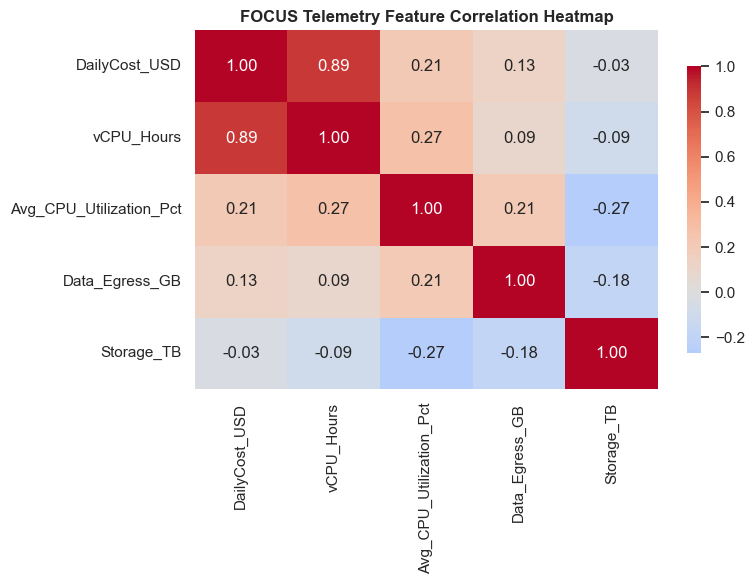

In [2]:
feature_cols = [
    "DailyCost_USD", "vCPU_Hours", "Avg_CPU_Utilization_Pct", 
    "Data_Egress_GB", "Storage_TB"
]

plt.figure(figsize=(8, 6))
corr = df[feature_cols].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, cbar_kws={'shrink': 0.8})
plt.title("FOCUS Telemetry Feature Correlation Heatmap", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()


### Block 3: Gold-Standard Temporal Train-Test Split (No Lookahead Leakage)
We enforce a chronological split where the final 15% of the timeline is held out as an unseen out-of-time test set. Random shuffling is strictly prohibited.


In [3]:
train_df, test_df = temporal_train_test_split(df, date_col="Date", test_ratio=0.15)
print(f"Train Period: {train_df['Date'].min().strftime('%Y-%m-%d')} to {train_df['Date'].max().strftime('%Y-%m-%d')} ({len(train_df):,} rows)")
print(f"Test Period:  {test_df['Date'].min().strftime('%Y-%m-%d')} to {test_df['Date'].max().strftime('%Y-%m-%d')} ({len(test_df):,} rows)")


[Temporal Split] Total: 32,850 rows | Train: 27,922 rows (2025-01-01 to 2025-11-07) | Test Holdout: 4,928 rows (2025-11-07 to 2025-12-31)
Train Period: 2025-01-01 to 2025-11-07 (27,922 rows)
Test Period:  2025-11-07 to 2025-12-31 (4,928 rows)


### Block 4: 5-Fold TimeSeriesSplit (Expanding Window Cross-Validation)
We perform 5-fold temporal expanding window cross-validation across the chronological sequence to verify out-of-sample precision, recall, and ROC-AUC stability.


In [4]:
validator = FinOpsTimeSeriesValidator(n_splits=5)
anomaly_cv_results = validator.evaluate_anomaly_cv(FinOpsAnomalyDetector, df, ground_truth_col="Is_Anomaly")

print("=== 5-Fold TimeSeriesSplit Cross-Validation Results ===")
display_cols = ["Fold", "Train_Size", "Test_Size", "Precision", "Recall", "F1_Score", "ROC_AUC", "PR_AUC"]
print(anomaly_cv_results["folds"][display_cols].to_string(index=False))

print(f"\nMean Precision across Folds: {anomaly_cv_results['mean_precision']:.4f}")
print(f"Mean Recall across Folds:    {anomaly_cv_results['mean_recall']:.4f}")
print(f"Mean F1-Score across Folds:  {anomaly_cv_results['mean_f1']:.4f}")
print(f"Mean ROC-AUC across Folds:   {anomaly_cv_results['mean_roc_auc']:.4f}")
print(f"Mean PR-AUC across Folds:    {anomaly_cv_results['mean_pr_auc']:.4f}")


=== 5-Fold TimeSeriesSplit Cross-Validation Results ===
 Fold  Train_Size  Test_Size  Precision  Recall  F1_Score  ROC_AUC  PR_AUC
    1        5475       5475     0.5522  1.0000    0.7115   0.9903  0.6369
    2       10950       5475     0.4975  1.0000    0.6644   0.9952  0.8669
    3       16425       5475     0.5500  0.9091    0.6854   0.9920  0.8730
    4       21900       5475     0.3252  0.8889    0.4762   0.9487  0.7038
    5       27375       5475     0.4452  0.9200    0.6000   0.9848  0.8063

Mean Precision across Folds: 0.4740
Mean Recall across Folds:    0.9436
Mean F1-Score across Folds:  0.6275
Mean ROC-AUC across Folds:   0.9822
Mean PR-AUC across Folds:    0.7774


### Block 5: Systematic Hyperparameter Optimization (Grid Search)
We systematically evaluate candidate Isolation Forest contamination rates and estimator counts using strictly temporal validation.


In [5]:
param_grid = {
    "contamination": [0.015, 0.0184, 0.022],
    "n_estimators": [150, 200],
    "max_samples": [0.8, 1.0]
}
tuner = FinOpsHyperparameterOptimizer()
tuning_results = tuner.tune_anomaly_detector(df, FinOpsAnomalyDetector, param_grid=param_grid, n_splits=3)
print(f"Optimal Hyperparameters: {tuning_results['best_params']}")
print(f"Best Cross-Validation F1-Score: {tuning_results['best_f1']:.4f}")
tuning_results["results_df"].head(5)


[*] Starting Anomaly Detector Hyperparameter Search (12 candidate configurations)...


[+] Optimization Complete. Best Parameters: {'contamination': 0.015, 'max_samples': 1.0, 'n_estimators': 200} | Best Mean F1: 0.7209
Optimal Hyperparameters: {'contamination': 0.015, 'max_samples': 1.0, 'n_estimators': 200}
Best Cross-Validation F1-Score: 0.7209


,contamination,max_samples,n_estimators,Mean_Precision,Mean_Recall,Mean_F1,Mean_ROC_AUC,Mean_PR_AUC
0,0.0150,1.0,200,0.5800,0.9540,0.7209,0.9898,0.7428
1,0.0150,0.8,200,0.5768,0.9491,0.7174,0.9896,0.7531
2,0.0150,0.8,150,0.5724,0.9466,0.7132,0.9891,0.7451
3,0.0150,1.0,150,0.5694,0.9515,0.7121,0.9899,0.7406
4,0.0184,0.8,200,0.5037,0.9607,0.6608,0.9896,0.7533


### Block 6: Production Model Fit & Out-of-Time Holdout Evaluation
We fit the calibrated `FinOpsAnomalyDetector` on the chronological training set and score the out-of-time holdout test set.


In [6]:
detector = FinOpsAnomalyDetector(contamination=0.0184)
detector.fit(train_df)
test_evaluated = detector.predict(test_df)

y_true = test_df["Is_Anomaly"].values.astype(int)
y_pred = test_evaluated["detected_anomaly"].values.astype(int)
y_scores = test_evaluated["anomaly_score"].values

print("=== Classification Report (Holdout Test Set) ===")
print(classification_report(y_true, y_pred, target_names=["Normal", "Anomaly"], digits=4))
print(f"Holdout ROC-AUC Score: {roc_auc_score(y_true, y_scores):.4f}")
print(f"Holdout PR-AUC Score:  {average_precision_score(y_true, y_scores):.4f}")


=== Classification Report (Holdout Test Set) ===
              precision    recall  f1-score   support

      Normal     0.9949    0.9747    0.9847      4783
     Anomaly     0.5000    0.8345    0.6253       145

    accuracy                         0.9706      4928
   macro avg     0.7474    0.9046    0.8050      4928
weighted avg     0.9803    0.9706    0.9741      4928

Holdout ROC-AUC Score: 0.9758
Holdout PR-AUC Score:  0.6943


### Block 7: Comprehensive Diagnostic Visualization Suite
We render the full 6-panel diagnostic dashboard:
1. Annotated Confusion Matrix
2. Precision-Recall Trade-off Curve (AP)
3. ROC Discrimination Curve (AUC)
4. Anomaly Score Density Distribution (Normal vs Anomalous KDE)
5. Telemetry Feature Correlation Heatmap
6. Validation Performance Metrics Summary


[+] Saved Anomaly Diagnostic Plot to: assets/anomaly_detection_diagnostics.png


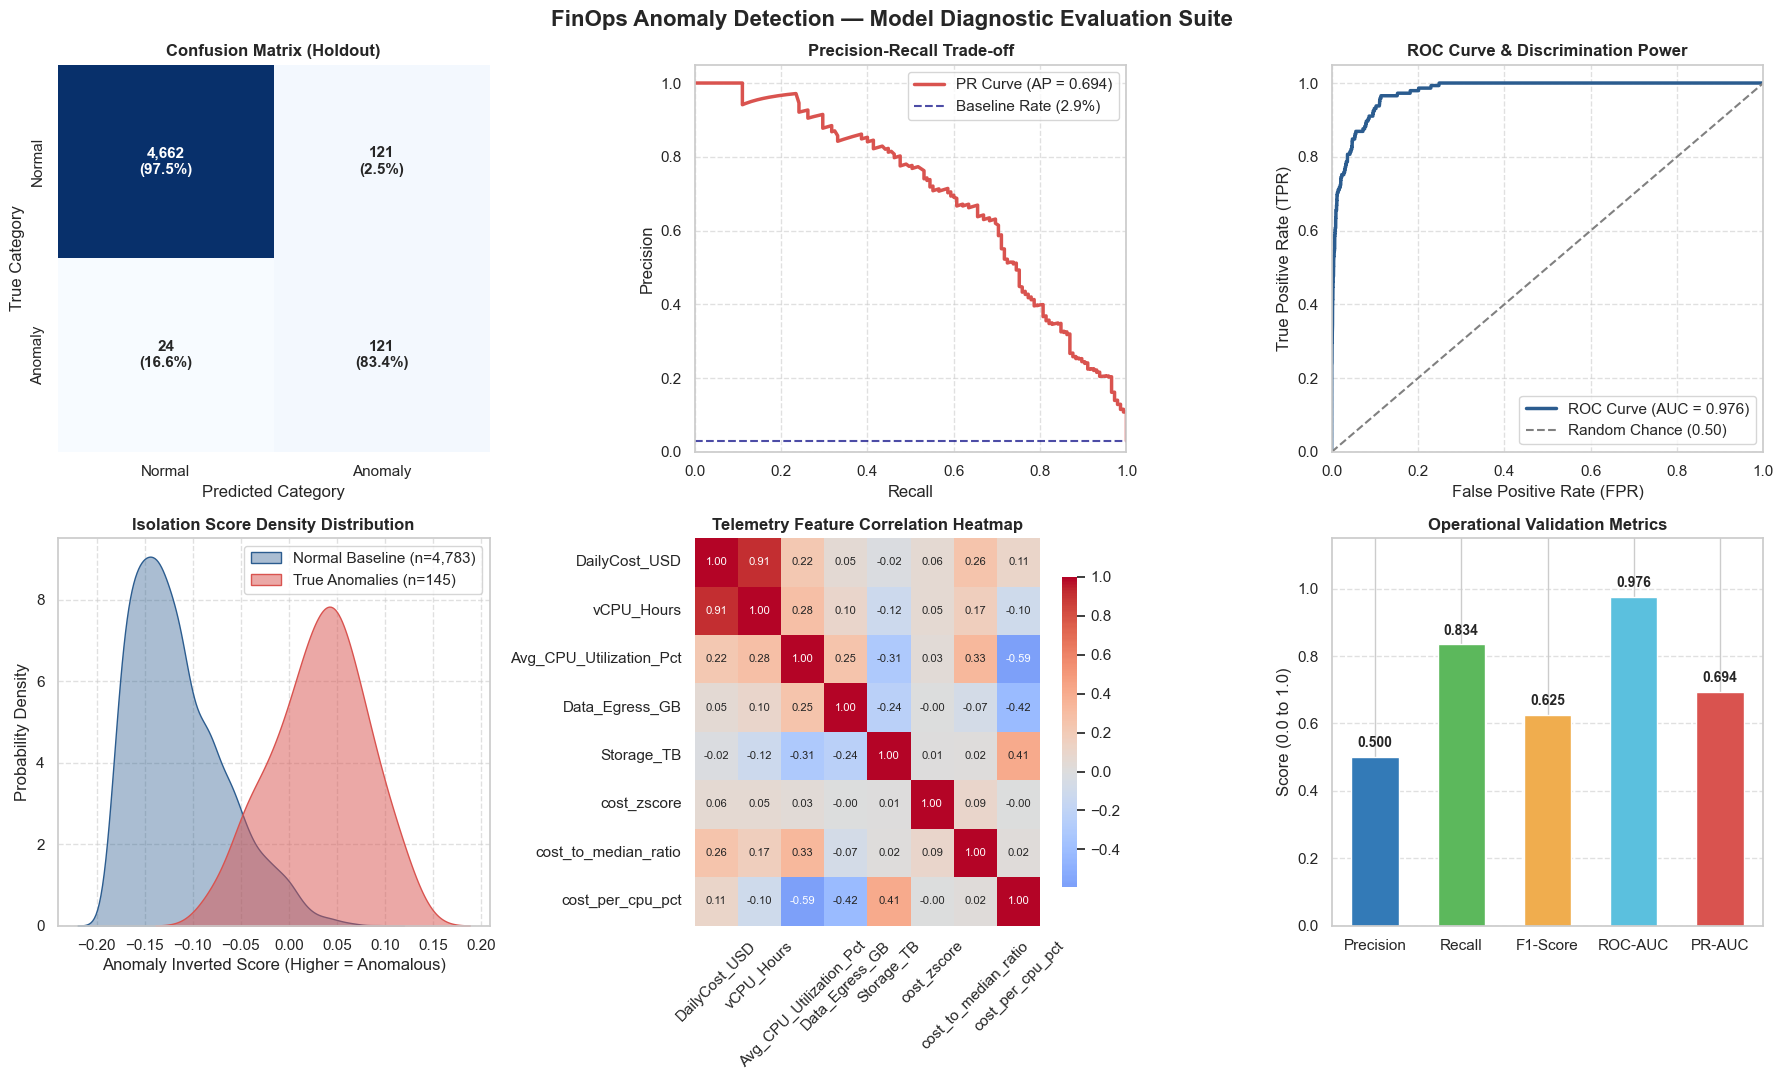

In [7]:
fig = FinOpsDiagnosticSuite.plot_anomaly_diagnostics(
    y_true=y_true,
    y_pred=y_pred,
    y_scores=y_scores,
    feature_df=test_evaluated,
    save_path="assets/anomaly_detection_diagnostics.png"
)
plt.show()


### Block 8: Multi-Cloud Machine Image & Disk Snapshot Waste Analysis
We isolate anomalies attributed to stale machine images and orphan disk snapshots across AWS EBS, Azure Disks, and GCP Compute Engine.


In [8]:
snapshot_anomalies = test_evaluated[
    (test_evaluated['Is_Anomaly']) & 
    (test_evaluated['Diagnostic_Root_Cause'].str.contains('Snapshot|Machine Image|Storage', case=False, na=False))
]

print(f"Snapshot/Storage Anomalies Detected: {len(snapshot_anomalies):,}")
print(f"Total Snapshot Waste Spend in Holdout: ${snapshot_anomalies['DailyCost_USD'].sum():,.2f}")
print(f"Average Waste Cost per Incident: ${snapshot_anomalies['Waste_Cost_USD'].mean():,.2f}")

snapshot_anomalies[['Date', 'Provider', 'Service', 'ResourceName', 'DailyCost_USD', 'Storage_TB', 'Anomaly_Severity', 'Diagnostic_Root_Cause']].head(8)


Snapshot/Storage Anomalies Detected: 26
Total Snapshot Waste Spend in Holdout: $7,141.81
Average Waste Cost per Incident: $118.24


,Date,Provider,Service,ResourceName,DailyCost_USD,Storage_TB,Anomaly_Severity,Diagnostic_Root_Cause
255,2025-11-10,GCP,Cloud Storage (Storage),goo-cloud -b3b2cfce,238.28,24.07,CRITICAL,Storage Sprawl: Orphan snapshots or unattached...
258,2025-11-10,Azure,Microsoft.Storage (Storage),azu-micros-f2901aff,81.17,69.29,CRITICAL,Storage Sprawl: Orphan snapshots or unattached...
300,2025-11-10,AWS,AmazonS3 (Storage),aws-amazon-f0c7344d,134.40,48.06,MEDIUM,Storage Sprawl: Orphan snapshots or unattached...
429,2025-11-12,GCP,Cloud Storage (Storage),goo-cloud -41c3bc10,425.45,59.20,CRITICAL,Storage Sprawl: Orphan snapshots or unattached...
439,2025-11-12,Azure,Microsoft.Storage (Storage),azu-micros-790af162,142.80,26.12,CRITICAL,Storage Sprawl: Orphan snapshots or unattached...
445,2025-11-12,Azure,Microsoft.Storage (Storage),azu-micros-7cbf20ec,358.06,34.54,CRITICAL,Storage Sprawl: Orphan snapshots or unattached...
446,2025-11-12,GCP,Cloud Storage (Storage),goo-cloud -402939c7,286.32,27.11,CRITICAL,Storage Sprawl: Orphan snapshots or unattached...
456,2025-11-12,GCP,Cloud Storage (Storage),goo-cloud -b1779c5e,141.31,30.37,CRITICAL,Storage Sprawl: Orphan snapshots or unattached...


### Block 9: Root-Cause Diagnostic Categorization & Severity Matrix


In [9]:
root_cause_summary = test_evaluated[test_evaluated['Is_Anomaly']].groupby('Diagnostic_Root_Cause').agg({
    'ResourceName': 'count',
    'DailyCost_USD': 'sum',
    'Waste_Cost_USD': 'sum'
}).rename(columns={'ResourceName': 'Incident_Count'}).sort_values(by='Waste_Cost_USD', ascending=False)

root_cause_summary['Waste_Cost_USD'] = root_cause_summary['Waste_Cost_USD'].map('${:,.2f}'.format)
root_cause_summary['DailyCost_USD'] = root_cause_summary['DailyCost_USD'].map('${:,.2f}'.format)
print("=== Root Cause Breakdown ===")
print(root_cause_summary)

print("\n=== Severity Distribution ===")
print(test_evaluated[test_evaluated['Is_Anomaly']]['Anomaly_Severity'].value_counts())


=== Root Cause Breakdown ===
                                                    Incident_Count  \
Diagnostic_Root_Cause                                                
Zombie/Idle Cluster: High compute allocation wi...             126   
Storage Sprawl: Orphan snapshots or unattached ...              26   
Unbudgeted Cost Surge: Spend exceeded statistic...              70   
Runaway Egress Spike: Massive outbound data tra...              20   

                                                   DailyCost_USD  \
Diagnostic_Root_Cause                                              
Zombie/Idle Cluster: High compute allocation wi...    $49,231.86   
Storage Sprawl: Orphan snapshots or unattached ...     $7,141.81   
Unbudgeted Cost Surge: Spend exceeded statistic...    $38,773.53   
Runaway Egress Spike: Massive outbound data tra...     $8,646.71   

                                                   Waste_Cost_USD  
Diagnostic_Root_Cause                                              
Zombi

### Block 10: Multi-Cloud Spend Timeline with Anomaly Incidents


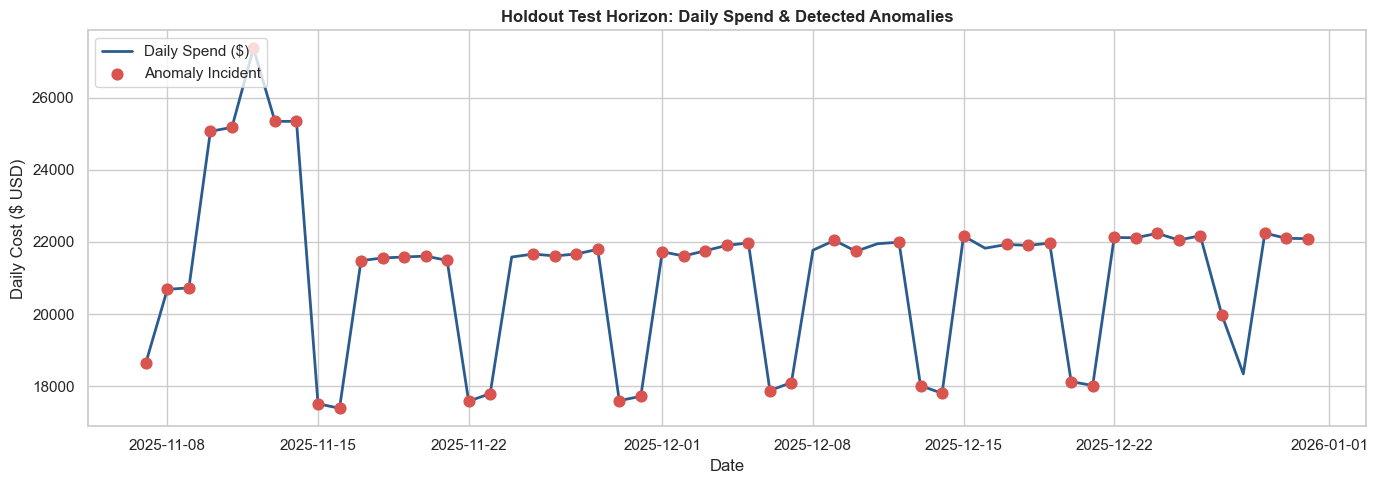

In [10]:
plt.figure(figsize=(14, 5))

daily_timeline = test_evaluated.groupby('Date').agg({
    'DailyCost_USD': 'sum',
    'detected_anomaly': 'sum'
}).reset_index()

plt.plot(daily_timeline['Date'], daily_timeline['DailyCost_USD'], color='#2b5c8f', label='Daily Spend ($)', linewidth=2)
anomaly_events = daily_timeline[daily_timeline['detected_anomaly'] > 0]
plt.scatter(anomaly_events['Date'], anomaly_events['DailyCost_USD'], color='#d9534f', s=60, zorder=5, label='Anomaly Incident')

plt.title("Holdout Test Horizon: Daily Spend & Detected Anomalies", fontsize=12, fontweight='bold')
plt.xlabel("Date")
plt.ylabel("Daily Cost ($ USD)")
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()


### Block 11: Production MLOps Model Serialization & Disk Persistence
Persist the trained, calibrated Isolation Forest weights to `models/anomaly_detector_isolation_forest.joblib` for zero-latency warm starts in the FastAPI serving layer.


In [11]:
import os, joblib
models_dir = os.path.join("..", "models")
os.makedirs(models_dir, exist_ok=True)
model_path = os.path.join(models_dir, "anomaly_detector_isolation_forest.joblib")
detector.save(model_path)
file_size_kb = os.path.getsize(model_path) / 1024
print(f"[+] Successfully serialized trained Anomaly Detector to: {model_path} ({file_size_kb:.1f} KB)")

# Test instant warm load
loaded_detector = FinOpsAnomalyDetector.load(model_path)
print(f"[+] Verified warm load from disk: {len(loaded_detector.model.estimators_)} trees ready for production inference.")


[+] Successfully serialized trained Anomaly Detector to: ..\models\anomaly_detector_isolation_forest.joblib (2203.0 KB)
[+] Verified warm load from disk: 200 trees ready for production inference.
